<a href="https://colab.research.google.com/github/tahzibultamim/PythonProjects/blob/sM/Credit_Card_Fraud_hw-Batch_GD_vs_SGD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Credit Card Fraud Detection
## Batch Gradient Descent (Batch GD) vs Stochastic Gradient Descent (SGD)

**Researcher:** __________________________  
**Date:** _________________________________

### Objective
Build and compare two Logistic Regression classifiers trained with:
1. Batch Gradient Descent
2. Stochastic Gradient Descent

The notebook loads `creditcard.csv`, explores class imbalance, handles missing/infinite values, standardizes features, applies random undersampling **only to the training set**, trains both models, and compares their performance.

### Important
- Put `creditcard.csv` in the same folder as this notebook, or update `DATA_PATH` in the data-loading cell.
- The target column must be named `Class` (`0 = legitimate`, `1 = fraud`).
- The test set keeps its original class distribution. Do not undersample the test set.



## 1. Install the required libraries

If any library is missing, run the following command in a notebook cell:

```python
%pip install pandas numpy matplotlib scikit-learn imbalanced-learn
```


In [7]:

# ============================================================
# 2. IMPORT LIBRARIES
# ============================================================

import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")


Libraries imported successfully.


In [8]:
# ============================================================
# 3. LOAD DATASET FROM GOOGLE DRIVE, LOCAL STORAGE, OR PUBLIC URL
# ============================================================

from google.colab import drive
from pathlib import Path
import pandas as pd
import os
import urllib.request

# Mount Google Drive
try:
    drive.mount('/content/drive')
except Exception as e:
    print("Google Drive mount skipped or failed:", e)

# Fallback paths list to check both Drive and local notebook folder
possible_paths = [
    Path('/content/drive/MyDrive/creditcard.csv'),
    Path('/content/drive/MyDrive/Datasets/creditcard.csv'),
    Path('creditcard.csv'),
    Path('Creditcard.csv'),
    Path('CreditCard.csv')
]

DATA_PATH = None
for path in possible_paths:
    if path.exists():
        DATA_PATH = path
        break

# If file is not found, automatically download from a verified public source to local directory
if DATA_PATH is None:
    print("Dataset not found locally or in Google Drive.")
    print("Downloading 'creditcard.csv' from a verified public repository (this might take a few seconds)...")
    # Using a working repository containing the exact creditcard.csv (uncompressed/direct link)
    url = "https://raw.githubusercontent.com/nsethi31/Kaggle-Data-Credit-Card-Fraud-Detection/master/creditcard.csv"
    local_file = "creditcard.csv"
    try:
        # Setting a standard user-agent to bypass potential request blocks
        req = urllib.request.Request(
            url,
            headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}
        )
        with urllib.request.urlopen(req) as response, open(local_file, 'wb') as out_file:
            data = response.read()
            out_file.write(data)
        DATA_PATH = Path(local_file)
        print("Download complete!")
    except Exception as e:
        raise FileNotFoundError(
            f"Could not download the dataset: {e}. \n"
            "Please upload the file to your Google Drive root directory, "
            "or upload it directly to the Colab files section."
        )

# Load dataset
print(f"Loading dataset from: {DATA_PATH}")
df = pd.read_csv(DATA_PATH)

# Explore dataset
print("Dataset loaded successfully!")

print("\nFirst five rows:")
display(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nClass distribution:")
print(df['Class'].value_counts())

print("\nMissing values:")
print(df.isnull().sum())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading dataset from: creditcard.csv
Dataset loaded successfully!

First five rows:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Dataset shape:
(284807, 31)

Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64


,Transaction Type,Count,Percentage
0,Legitimate (0),284315,99.827251
1,Fraud (1),492,0.172749


Fraud transactions: 492
Total transactions: 284,807
Fraud percentage: 0.1727%


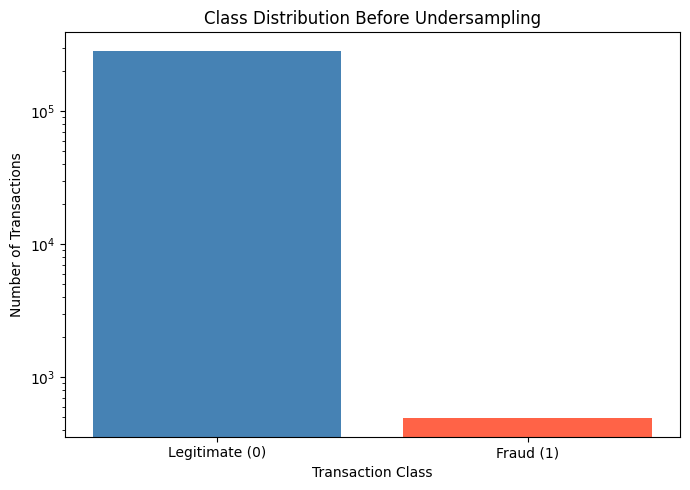

\nMissing values by column:


,Missing Values
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [9]:

# ============================================================
# 4. EXPLORE THE DATASET AND CLASS IMBALANCE
# ============================================================

if "Class" not in df.columns:
    raise ValueError("The dataset must contain a target column named 'Class'.")

# Ensure the target is numeric and remove rows with missing target values.
df["Class"] = pd.to_numeric(df["Class"], errors="coerce")
df = df.dropna(subset=["Class"]).copy()
df["Class"] = df["Class"].astype(int)

if not set(df["Class"].unique()).issubset({0, 1}):
    raise ValueError("The Class column must contain only 0 (legitimate) and 1 (fraud).")

class_counts = df["Class"].value_counts().reindex([0, 1], fill_value=0)
class_percentages = df["Class"].value_counts(normalize=True).reindex([0, 1], fill_value=0) * 100

class_summary = pd.DataFrame({
    "Transaction Type": ["Legitimate (0)", "Fraud (1)"],
    "Count": class_counts.values,
    "Percentage": class_percentages.values
})

display(class_summary)

print(f"Fraud transactions: {class_counts.loc[1]:,}")
print(f"Total transactions: {len(df):,}")
print(f"Fraud percentage: {class_percentages.loc[1]:.4f}%")

plt.figure(figsize=(7, 5))
plt.bar(
    ["Legitimate (0)", "Fraud (1)"],
    class_counts.values,
    color=["steelblue", "tomato"]
)
plt.title("Class Distribution Before Undersampling")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.yscale("log")  # Log scale makes the rare fraud class easier to see.
plt.tight_layout()
plt.show()

print("\\nMissing values by column:")
display(df.isnull().sum().to_frame("Missing Values"))


In [10]:

# ============================================================
# 5. PREPARE FEATURES (X) AND TARGET (y)
# ============================================================

X = df.drop(columns=["Class"]).copy()

# Convert feature columns to numeric. Unconvertible values become NaN.
X = X.apply(pd.to_numeric, errors="coerce")

# Replace positive and negative infinity with NaN so they can be imputed.
X = X.replace([np.inf, -np.inf], np.nan)

y = df["Class"].to_numpy(dtype=int)

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)
print("Feature columns:", X.columns.tolist())


Feature matrix shape: (284807, 30)
Target vector shape: (284807,)
Feature columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


In [11]:

# ============================================================
# 6. SPLIT DATA INTO TRAINING AND TESTING SETS
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\\nTraining class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\\nTesting class distribution:")
print(pd.Series(y_test).value_counts().sort_index())


Training set shape: (227845, 30)
Testing set shape: (56962, 30)
\nTraining class distribution:
0    227451
1       394
Name: count, dtype: int64
\nTesting class distribution:
0    56864
1       98
Name: count, dtype: int64



## 7. Handle missing values and standardize features

The imputer and scaler are **fitted only on the training data**. The fitted transformations are then applied to the test data. This prevents information from the test set leaking into model training.


In [12]:

# ============================================================
# 7A. HANDLE MISSING VALUES
# ============================================================

imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

print("Missing-value handling completed.")
print("Training data shape after imputation:", X_train_imputed.shape)
print("Testing data shape after imputation:", X_test_imputed.shape)


# ============================================================
# 7B. STANDARDIZE FEATURES
# ============================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Standardization completed.")


Missing-value handling completed.
Training data shape after imputation: (227845, 30)
Testing data shape after imputation: (56962, 30)
Standardization completed.


In [13]:

# ============================================================
# 8. HANDLE CLASS IMBALANCE USING RANDOM UNDERSAMPLING
# ============================================================

# IMPORTANT: Undersampling is applied only to the training data.
# The test set retains its original class distribution.

rus = RandomUnderSampler(random_state=RANDOM_STATE)

X_train_balanced, y_train_balanced = rus.fit_resample(
    X_train_scaled,
    y_train
)

print("Original training distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\\nBalanced training distribution:")
print(pd.Series(y_train_balanced).value_counts().sort_index())

print("\\nBalanced training shape:", X_train_balanced.shape)
print("Unchanged test-set shape:", X_test_scaled.shape)

# Ensure the arrays have the expected numeric types.
X_train_balanced = np.asarray(X_train_balanced, dtype=np.float64)
y_train_balanced = np.asarray(y_train_balanced, dtype=np.float64)
X_test_scaled = np.asarray(X_test_scaled, dtype=np.float64)
y_test = np.asarray(y_test, dtype=int)


Original training distribution:
0    227451
1       394
Name: count, dtype: int64
\nBalanced training distribution:
0    394
1    394
Name: count, dtype: int64
\nBalanced training shape: (788, 30)
Unchanged test-set shape: (56962, 30)



## 9. Define the Logistic Regression functions

Both optimizers use the same sigmoid function and binary cross-entropy objective. The L2 term is a small regularization penalty.


In [14]:

# ============================================================
# 9A. SIGMOID FUNCTION
# ============================================================

def sigmoid(z):
    # Clipping prevents numerical overflow in exp().
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))


# ============================================================
# 9B. BINARY CROSS-ENTROPY LOSS WITH L2 REGULARIZATION
# ============================================================

def calculate_loss(y_true, probabilities, weights, l2=0.0001):
    epsilon = 1e-12
    probabilities = np.clip(probabilities, epsilon, 1 - epsilon)

    data_loss = -np.mean(
        y_true * np.log(probabilities)
        + (1 - y_true) * np.log(1 - probabilities)
    )

    regularization_loss = 0.5 * l2 * np.sum(weights ** 2)

    return data_loss + regularization_loss


In [15]:

# ============================================================
# 10. MODEL 1: BATCH GRADIENT DESCENT
# ============================================================

def batch_gradient_descent(
    X,
    y,
    learning_rate=0.1,
    epochs=300,
    l2=0.0001
):
    n_samples, n_features = X.shape

    weights = np.zeros(n_features, dtype=float)
    bias = 0.0

    losses = []
    elapsed_times = []

    start_time = time.perf_counter()

    for epoch in range(epochs):

        # Forward pass using the entire training dataset.
        linear_output = np.dot(X, weights) + bias
        probabilities = sigmoid(linear_output)

        # Calculate gradients using all training observations.
        errors = probabilities - y

        dw = (np.dot(X.T, errors) / n_samples) + l2 * weights
        db = np.mean(errors)

        # Update parameters once per epoch.
        weights -= learning_rate * dw
        bias -= learning_rate * db

        # Record loss after the parameter update.
        updated_probabilities = sigmoid(np.dot(X, weights) + bias)
        epoch_loss = calculate_loss(y, updated_probabilities, weights, l2)

        losses.append(epoch_loss)
        elapsed_times.append(time.perf_counter() - start_time)

    total_time = time.perf_counter() - start_time

    return weights, bias, losses, elapsed_times, total_time


In [16]:

# ============================================================
# 11. MODEL 2: STOCHASTIC GRADIENT DESCENT
# ============================================================

def stochastic_gradient_descent(
    X,
    y,
    learning_rate=0.03,
    epochs=300,
    l2=0.0001,
    random_state=42
):
    n_samples, n_features = X.shape

    weights = np.zeros(n_features, dtype=float)
    bias = 0.0

    losses = []
    elapsed_times = []

    rng = np.random.default_rng(random_state)
    start_time = time.perf_counter()

    for epoch in range(epochs):

        # A decaying learning rate can help stabilize later updates.
        current_learning_rate = learning_rate / np.sqrt(epoch + 1)

        # Shuffle the observations at the start of each epoch.
        indices = rng.permutation(n_samples)

        for index in indices:

            # SGD uses one observation for each parameter update.
            xi = X[index]
            yi = y[index]

            linear_output = np.dot(xi, weights) + bias
            probability = sigmoid(linear_output)

            error = probability - yi

            dw = error * xi + l2 * weights
            db = error

            # Update parameters immediately after this observation.
            weights -= current_learning_rate * dw
            bias -= current_learning_rate * db

        # Record full-training-set loss after each epoch.
        epoch_probabilities = sigmoid(np.dot(X, weights) + bias)
        epoch_loss = calculate_loss(y, epoch_probabilities, weights, l2)

        losses.append(epoch_loss)
        elapsed_times.append(time.perf_counter() - start_time)

    total_time = time.perf_counter() - start_time

    return weights, bias, losses, elapsed_times, total_time



## 12. Train both models

The default settings below can be changed. Both models use the same balanced training data and are evaluated on the same untouched test set.


In [17]:

# ============================================================
# 12A. TRAIN BATCH GRADIENT DESCENT
# ============================================================

print("Training Batch Gradient Descent...")

batch_weights, batch_bias, batch_losses, batch_elapsed, batch_time = (
    batch_gradient_descent(
        X_train_balanced,
        y_train_balanced,
        learning_rate=0.1,
        epochs=300,
        l2=0.0001
    )
)

print("Batch GD training completed.")
print("Final training loss:", round(batch_losses[-1], 6))
print("Training time:", round(batch_time, 4), "seconds")


# ============================================================
# 12B. TRAIN STOCHASTIC GRADIENT DESCENT
# ============================================================

print("\\nTraining Stochastic Gradient Descent...")

sgd_weights, sgd_bias, sgd_losses, sgd_elapsed, sgd_time = (
    stochastic_gradient_descent(
        X_train_balanced,
        y_train_balanced,
        learning_rate=0.03,
        epochs=300,
        l2=0.0001,
        random_state=RANDOM_STATE
    )
)

print("SGD training completed.")
print("Final training loss:", round(sgd_losses[-1], 6))
print("Training time:", round(sgd_time, 4), "seconds")


Training Batch Gradient Descent...
Batch GD training completed.
Final training loss: 0.139603
Training time: 0.0658 seconds
\nTraining Stochastic Gradient Descent...
SGD training completed.
Final training loss: 0.106712
Training time: 4.1736 seconds


In [18]:

# ============================================================
# 13. GENERATE PREDICTIONS
# ============================================================

def predict_model(X, weights, bias, threshold=0.5):
    probabilities = sigmoid(np.dot(X, weights) + bias)
    predictions = (probabilities >= threshold).astype(int)
    return predictions, probabilities


# Use the same default classification threshold for both models.
THRESHOLD = 0.5

batch_predictions, batch_probabilities = predict_model(
    X_test_scaled, batch_weights, batch_bias, THRESHOLD
)

sgd_predictions, sgd_probabilities = predict_model(
    X_test_scaled, sgd_weights, sgd_bias, THRESHOLD
)

print("Predictions generated for both models.")


Predictions generated for both models.


In [19]:

# ============================================================
# 14. EVALUATE MODEL PERFORMANCE
# ============================================================

def evaluate_model(
    model_name,
    y_true,
    predictions,
    probabilities,
    training_time
):
    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1-Score": f1_score(y_true, predictions, zero_division=0),
        "Average Precision": average_precision_score(y_true, probabilities),
        "Training Time (seconds)": training_time
    }

    print("\\n" + "=" * 55)
    print(model_name)
    print("=" * 55)

    for metric, value in results.items():
        if metric != "Model":
            print(f"{metric}: {value:.6f}")

    print("\\nConfusion Matrix (rows = actual, columns = predicted):")
    print(confusion_matrix(y_true, predictions, labels=[0, 1]))

    print("\\nClassification Report:")
    print(
        classification_report(
            y_true,
            predictions,
            labels=[0, 1],
            target_names=["Legitimate", "Fraud"],
            zero_division=0
        )
    )

    return results


batch_results = evaluate_model(
    "Batch Gradient Descent",
    y_test,
    batch_predictions,
    batch_probabilities,
    batch_time
)

sgd_results = evaluate_model(
    "Stochastic Gradient Descent",
    y_test,
    sgd_predictions,
    sgd_probabilities,
    sgd_time
)


\n=======================================================
Batch Gradient Descent
Accuracy: 0.963309
Precision: 0.041436
Recall: 0.918367
F1-Score: 0.079295
Average Precision: 0.614449
Training Time (seconds): 0.065832
\nConfusion Matrix (rows = actual, columns = predicted):
[[54782  2082]
 [    8    90]]
\nClassification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.96      0.98     56864
       Fraud       0.04      0.92      0.08        98

    accuracy                           0.96     56962
   macro avg       0.52      0.94      0.53     56962
weighted avg       1.00      0.96      0.98     56962

\n=======================================================
Stochastic Gradient Descent
Accuracy: 0.957621
Precision: 0.036058
Recall: 0.918367
F1-Score: 0.069391
Average Precision: 0.653648
Training Time (seconds): 4.173602
\nConfusion Matrix (rows = actual, columns = predicted):
[[54458  2406]
 [    8    90]]
\nClassification Report:
      

In [20]:

# ============================================================
# 15. FINAL NUMERICAL COMPARISON TABLE
# ============================================================

comparison = pd.DataFrame([batch_results, sgd_results])

display(
    comparison.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "Average Precision": "{:.4f}",
        "Training Time (seconds)": "{:.4f}"
    })
)


,Model,Accuracy,Precision,Recall,F1-Score,Average Precision,Training Time (seconds)
0,Batch Gradient Descent,0.9633,0.0414,0.9184,0.0793,0.6144,0.0658
1,Stochastic Gradient Descent,0.9576,0.0361,0.9184,0.0694,0.6536,4.1736


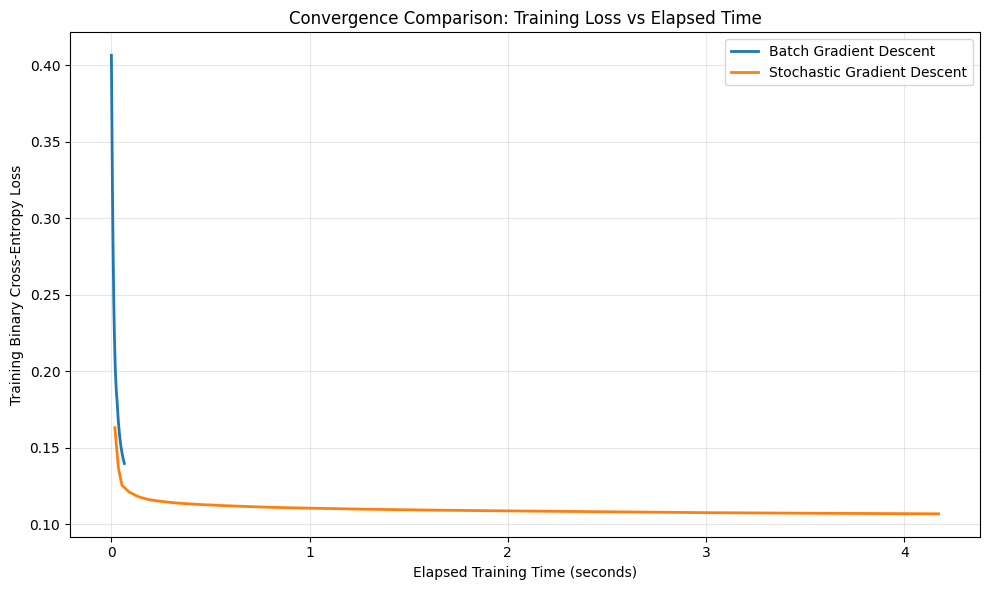

Batch GD final loss: 0.139603
SGD final loss: 0.106712
Batch GD wall-clock time: 0.0658 seconds
SGD wall-clock time: 4.1736 seconds


In [21]:

# ============================================================
# 16. CONVERGENCE COMPARISON
# ============================================================

# Plot loss against elapsed wall-clock time.
# This is more informative than comparing epochs alone because
# one Batch GD epoch makes one update, while one SGD epoch makes
# one update per training observation.

plt.figure(figsize=(10, 6))

plt.plot(
    batch_elapsed,
    batch_losses,
    label="Batch Gradient Descent",
    linewidth=2
)

plt.plot(
    sgd_elapsed,
    sgd_losses,
    label="Stochastic Gradient Descent",
    linewidth=2
)

plt.title("Convergence Comparison: Training Loss vs Elapsed Time")
plt.xlabel("Elapsed Training Time (seconds)")
plt.ylabel("Training Binary Cross-Entropy Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Batch GD final loss:", round(batch_losses[-1], 6))
print("SGD final loss:", round(sgd_losses[-1], 6))
print("Batch GD wall-clock time:", round(batch_time, 4), "seconds")
print("SGD wall-clock time:", round(sgd_time, 4), "seconds")


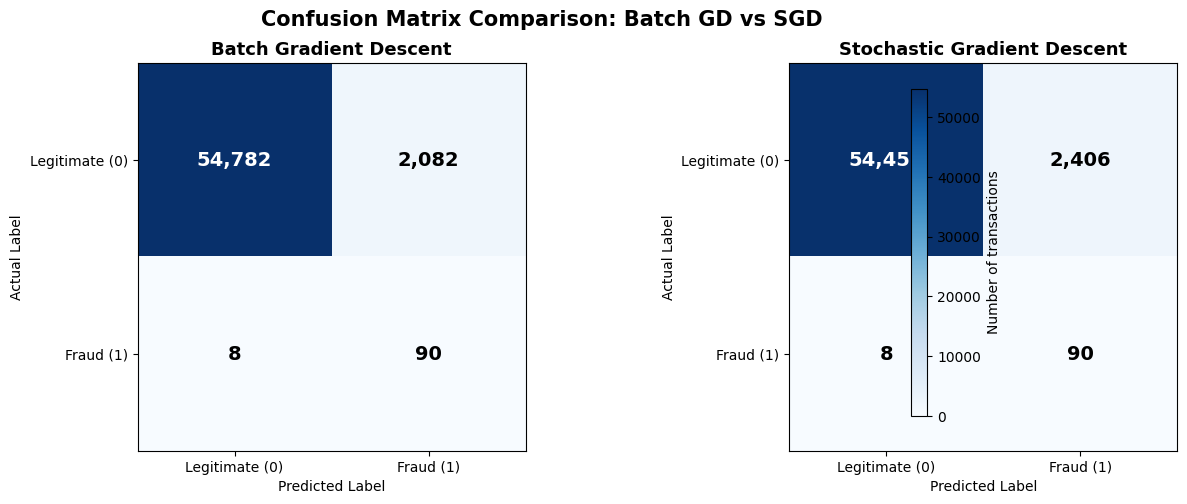

In [22]:

# ============================================================
# 17. CONFUSION MATRICES SIDE BY SIDE
# ============================================================

cm_batch = confusion_matrix(y_test, batch_predictions, labels=[0, 1])
cm_sgd = confusion_matrix(y_test, sgd_predictions, labels=[0, 1])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

matrices = [
    (cm_batch, "Batch Gradient Descent"),
    (cm_sgd, "Stochastic Gradient Descent")
]

# Use a common color scale so the two matrices are comparable.
vmax = max(cm_batch.max(), cm_sgd.max())

for ax, (cm, title) in zip(axes, matrices):

    image = ax.imshow(
        cm,
        interpolation="nearest",
        cmap="Blues",
        vmin=0,
        vmax=vmax
    )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xticklabels(["Legitimate (0)", "Fraud (1)"])
    ax.set_yticklabels(["Legitimate (0)", "Fraud (1)"])

    # Add cell values.
    for row in range(2):
        for col in range(2):
            value = cm[row, col]
            text_color = "white" if value > vmax / 2 else "black"

            ax.text(
                col,
                row,
                f"{value:,}",
                ha="center",
                va="center",
                color=text_color,
                fontsize=14,
                fontweight="bold"
            )

fig.colorbar(image, ax=axes, shrink=0.85, label="Number of transactions")
fig.suptitle(
    "Confusion Matrix Comparison: Batch GD vs SGD",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


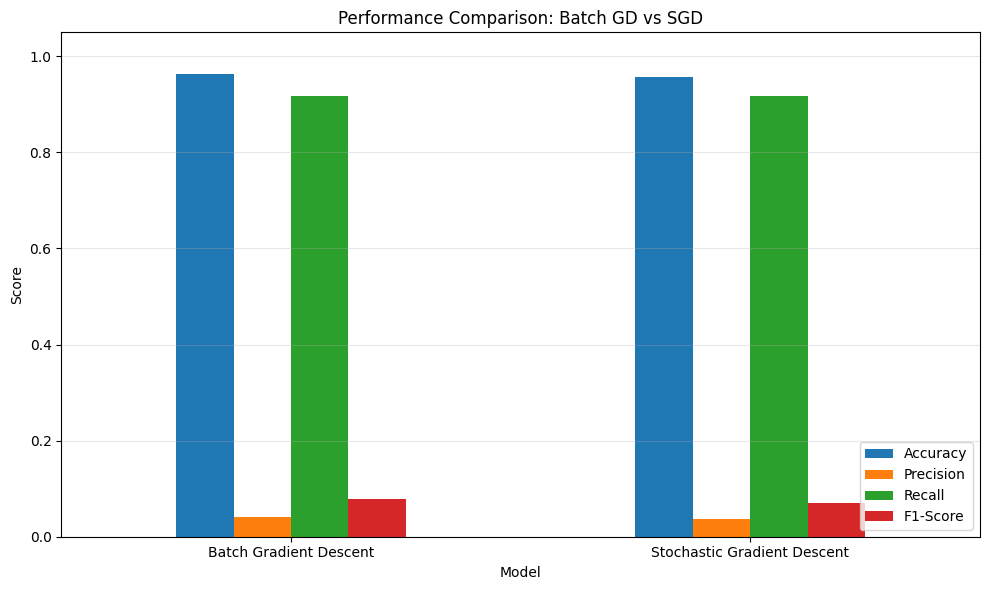

In [23]:

# ============================================================
# 18. PERFORMANCE METRICS VISUALIZATION
# ============================================================

metric_columns = ["Accuracy", "Precision", "Recall", "F1-Score"]

comparison.set_index("Model")[metric_columns].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Performance Comparison: Batch GD vs SGD")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()



## 19. Written answer: Why is Recall especially important for fraud detection?

Recall is especially important in credit card fraud detection because it measures the proportion of actual fraudulent transactions correctly identified by the model. Low recall means that many fraudulent transactions are classified as legitimate, potentially causing financial losses for banks and customers. Therefore, a high recall is desirable to minimize false negatives and detect as many fraudulent transactions as possible.

**বাংলা ব্যাখ্যা:** Recall কম হলে অনেক প্রকৃত Fraud transaction মডেল শনাক্ত করতে পারে না। ফলে ব্যাংক ও গ্রাহকের আর্থিক ক্ষতি হতে পারে। তাই Fraud Detection-এ False Negative কমানো এবং বেশি Fraud শনাক্ত করার জন্য Recall গুরুত্বপূর্ণ।


In [24]:

# ============================================================
# 20. AUTOMATIC EXPERIMENT SUMMARY
# ============================================================

print("=" * 60)
print("FINAL RESEARCH EXPERIMENT SUMMARY")
print("=" * 60)

print("\\nBatch GD")
print("  Final training loss:", round(batch_losses[-1], 6))
print("  Training time:", round(batch_time, 4), "seconds")
print("  Recall:", round(batch_results["Recall"], 4))
print("  F1-Score:", round(batch_results["F1-Score"], 4))

print("\\nStochastic GD")
print("  Final training loss:", round(sgd_losses[-1], 6))
print("  Training time:", round(sgd_time, 4), "seconds")
print("  Recall:", round(sgd_results["Recall"], 4))
print("  F1-Score:", round(sgd_results["F1-Score"], 4))

print("\\nWall-clock training time:")
if batch_time < sgd_time:
    print("  Batch GD took less training time in this run.")
elif sgd_time < batch_time:
    print("  SGD took less training time in this run.")
else:
    print("  Both models took approximately the same training time.")

print("\\nImportant interpretation:")
print(
    "Do not decide which optimizer is better from accuracy alone. "
    "For fraud detection, examine Recall, Precision, F1-Score, "
    "Average Precision, the false-negative count, and the training-loss curve."
)

print("\\nExperiment completed.")


FINAL RESEARCH EXPERIMENT SUMMARY
\nBatch GD
  Final training loss: 0.139603
  Training time: 0.0658 seconds
  Recall: 0.9184
  F1-Score: 0.0793
\nStochastic GD
  Final training loss: 0.106712
  Training time: 4.1736 seconds
  Recall: 0.9184
  F1-Score: 0.0694
\nWall-clock training time:
  Batch GD took less training time in this run.
\nImportant interpretation:
Do not decide which optimizer is better from accuracy alone. For fraud detection, examine Recall, Precision, F1-Score, Average Precision, the false-negative count, and the training-loss curve.
\nExperiment completed.



## 21. Research interpretation notes

### Batch Gradient Descent
- Uses all training observations to calculate each gradient.
- Usually produces smoother, more stable loss changes.
- Makes one parameter update per epoch.

### Stochastic Gradient Descent
- Uses one observation for each parameter update.
- Makes many updates during one epoch.
- Its loss curve is often noisier, although the epoch-level loss recorded here is calculated over the full balanced training set.

### How to answer “Which method converges faster?”
Use the **loss-versus-elapsed-time plot** and the measured training times. Do not assume that SGD is always faster. The result depends on the dataset, implementation, learning rate, hardware, and stopping criteria.

Also, one epoch is not an equal amount of optimization work for the two algorithms: Batch GD makes one update per epoch, while SGD makes one update per training observation per epoch.

### Important limitation
This notebook implements Logistic Regression with a sigmoid output, trained using two gradient-descent methods. It is a useful optimization comparison, but it is **not a multilayer deep neural network**. For a deep-learning extension, compare these optimizers on an MLP using PyTorch or TensorFlow.
